# Kingston University Coursework Brief 2026 2027

### Module Title: Applied Data Programming
### Assessment Title: Research Report and Visualisation

In [1]:
# pip install pandas numpy matplotlib jupyter

In [2]:
# Import required Library
import pandas as pd
import numpy as np

In [3]:
# 1. Load dataset
df = pd.read_csv("dataset_coursework1-1.csv", low_memory=False)
print("Original headers:", df.columns.tolist())

Original headers: ['Incident ID', 'Offence Code', 'CR Number', 'Dispatch Date / Time', 'Start_Date_Time', 'End_Date_Time', 'NIBRS Code', 'Victims', 'Crime Name1', 'Crime Name2', 'Crime Name3', 'Police District Name', 'Block Address', 'City', 'State', 'Zip Code', 'Agency', 'Place', 'Sector', 'Beat', 'PRA', 'Address Number', 'Street Prefix', 'Street Name', 'Street Suffix', 'Street Type', 'Latitude', 'Longitude', 'Police District Number', 'Location']


In [4]:
# If the first row was actually data (no header), reload with header=None
if str(df.columns[0]).strip().isdigit():
    df = pd.read_csv("dataset_coursework1-1.csv", header=None, low_memory=False)
print(df.columns[0])

Incident ID


In [5]:
# Assign standard 30-column NIBRS names by position
# The data set Titles are not follow up standerd to written names
canonical_cols = [
    "Incident ID", "Offense Code", "CR Number", "Dispatch Date/Time",
    "Start Date/Time", "End Date/Time", "NIBRS Code", "Victims",
    "Crime Name 1", "Crime Name 2", "Crime Name 3", "Police District Name",
    "Block Address", "City", "State", "Zip Code", "Agency", "Place",
    "Sector", "Beat", "PRA", "Address Number", "Street Prefix",
    "Street Name", "Street Suffix", "Street Type", "Latitude",
    "Longitude", "Police District Number", "Geolocation"
]

#### Replace Columns Name Standerd Patterns

In [6]:
if df.shape[1] == 30:
    df.columns = canonical_cols
else:
    raise ValueError(f"Expected 30 columns, found {df.shape[1]}. Check separator/encoding.")

#### How many rows and Columns in the Data set

In [7]:
total_raw_rows = len(df)
print(f"Total raw rows: {total_raw_rows:,} | Columns: {df.shape[1]}")

Total raw rows: 508,106 | Columns: 30


In [8]:
# 2. Initial Data Quality Audit (Quantifying Missingness & Noise)
audit = pd.DataFrame({
    "dtype": df.dtypes,
    "missing_count": df.isna().sum(),
    "missing_pct": (df.isna().sum() / total_raw_rows * 100).round(2),
    "unique_values": df.nunique()
})
print("\n--- Missingness & Cardinality Audit ---")
print(audit)


--- Missingness & Cardinality Audit ---
                          dtype  missing_count  missing_pct  unique_values
Incident ID               int64              0         0.00         467601
Offense Code                str              0         0.00            360
CR Number                 int64              0         0.00         467534
Dispatch Date/Time          str          73405        14.45         397963
Start Date/Time             str              0         0.00         372500
End Date/Time               str         282444        55.59         157941
NIBRS Code                  str              0         0.00             54
Victims                   int64              0         0.00             10
Crime Name 1                str              0         0.00              4
Crime Name 2                str              0         0.00             54
Crime Name 3                str              0         0.00            360
Police District Name        str           1542         0.30

In [9]:
# Ensure numeric types for Latitude/Longitude/Victims
for num_col in ["Latitude", "Longitude", "Victims"]:
    df[num_col] = pd.to_numeric(df[num_col], errors="coerce")

zero_coords = ((df["Latitude"] == 0.0) | (df["Longitude"] == 0.0)).sum()
null_coords = (df["Latitude"].isna() | df["Longitude"].isna()).sum()
print(f"\nZeroed Coordinates (0.0): {zero_coords:,} ({zero_coords/total_raw_rows*100:.2f}%)")
print(f"Null Coordinates (NaN):   {null_coords:,} ({null_coords/total_raw_rows*100:.2f}%)")


Zeroed Coordinates (0.0): 24,648 (4.85%)
Null Coordinates (NaN):   0 (0.00%)


In [10]:
# 3. Date Parsing & Temporal Consistency Check
date_cols = ["Dispatch Date/Time", "Start Date/Time", "End Date/Time"]
for col in date_cols:
    df[col] = pd.to_datetime(df[col], format="%m/%d/%Y %I:%M:%S %p", errors="coerce")

invalid_end = (df["End Date/Time"] < df["Start Date/Time"]).sum()
out_of_scope = ((df["Start Date/Time"] < "2016-07-01") | (df["Start Date/Time"] > "2026-09-10 23:59:59")).sum()
print(f"End Date < Start Date anomalies: {invalid_end:,} ({invalid_end/total_raw_rows*100:.2f}%)")
print(f"Out-of-scope timestamps:        {out_of_scope:,} ({out_of_scope/total_raw_rows*100:.2f}%)")

End Date < Start Date anomalies: 8,418 (1.66%)
Out-of-scope timestamps:        228 (0.04%)


In [11]:
# 4. Cleaning & Transformation
df_clean = df.copy()
df_clean.loc[(df_clean["Latitude"] == 0.0) | (df_clean["Longitude"] == 0.0), ["Latitude", "Longitude"]] = np.nan

df_clean["Dispatch_Status"] = np.where(df_clean["Dispatch Date/Time"].isna(), "Non-Dispatched", "Dispatched")
df_clean["Crime Name 1"] = df_clean["Crime Name 1"].fillna("Unknown / Unclassified")
df_clean["Police District Name"] = df_clean["Police District Name"].astype(str).str.strip().str.upper().replace("NAN", "UNKNOWN")
df_clean["City"] = df_clean["City"].astype(str).str.strip().str.upper().replace("NAN", "UNKNOWN")

df_clean.loc[df_clean["End Date/Time"] < df_clean["Start Date/Time"], "End Date/Time"] = pd.NaT

exact_dups = df_clean.duplicated(subset=["Incident ID"], keep=False).sum()
print(f"Exact duplicate Incident IDs dropped: {exact_dups:,}")


Exact duplicate Incident IDs dropped: 74,254


In [12]:
# Filter for all rows with a duplicated Incident ID
all_dups = df_clean[df_clean.duplicated(subset=["Incident ID"], keep=False)]

# Sort by Incident ID to group matching records together
all_dups = all_dups.sort_values(by="Incident ID")

print(f"Total rows involved in duplicates: {len(all_dups):,}")
display(all_dups) # Use print(all_dups) if not in a Jupyter notebook


Total rows involved in duplicates: 74,254


,Incident ID,Offense Code,CR Number,Dispatch Date/Time,Start Date/Time,End Date/Time,NIBRS Code,Victims,Crime Name 1,Crime Name 2,...,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Geolocation,Dispatch_Status
508079,201087097,5202,16033232,NaT,2016-07-01 00:04:00,NaT,520,1,Crime Against Society,Weapon Law Violations,...,13700.0,NaN,CONNECTICUT,NaN,AVE,39.07895,-77.0808,4D,"(39.0789, -77.0808)",Non-Dispatched
508078,201087097,5707,16033232,NaT,2016-07-01 00:04:00,NaT,90J,1,Crime Against Society,Trespass of Real Property,...,13700.0,NaN,CONNECTICUT,NaN,AVE,39.07895,-77.0808,4D,"(39.0789, -77.0808)",Non-Dispatched
508077,201087097,2303,16033232,NaT,2016-07-01 00:04:00,NaT,23C,1,Crime Against Property,Shoplifting,...,13700.0,NaN,CONNECTICUT,NaN,AVE,39.07895,-77.0808,4D,"(39.0789, -77.0808)",Non-Dispatched
508036,201087133,9199,16033268,NaT,2016-07-01 08:52:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,11800.0,NaN,ROCKVILLE,NaN,PIK,39.05040,-77.1148,2D,"(39.0504, -77.1148)",Non-Dispatched
508037,201087133,2602,16033268,NaT,2016-07-01 08:52:00,NaT,26A,1,Crime Against Property,False Pretenses/Swindle/Confidence Game,...,11800.0,NaN,ROCKVILLE,NaN,PIK,39.05040,-77.1148,2D,"(39.0504, -77.1148)",Non-Dispatched
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,201590537,4801,260040049,2026-09-12 22:07:57,2026-09-12 22:07:00,NaT,90Z,1,Crime Against Society,All Other Offenses,...,1.0,E,DEER PARK,NaN,DR,39.13218,-77.1889,6D,"(39.1322, -77.1889)",Dispatched
77,201590543,5299,260040058,2026-09-13 00:06:31,2026-09-13 00:06:00,NaT,520,1,Crime Against Society,Weapon Law Violations,...,7400.0,NaN,NEW HAMPSHIRE,NaN,AVE,38.98337,-76.9883,TPPD,"(38.9834, -76.9883)",Dispatched
76,201590543,5212,260040058,2026-09-13 00:06:31,2026-09-13 00:06:00,NaT,520,1,Crime Against Society,Weapon Law Violations,...,7400.0,NaN,NEW HAMPSHIRE,NaN,AVE,38.98337,-76.9883,TPPD,"(38.9834, -76.9883)",Dispatched
110,201590553,1399,260040016,2026-09-12 16:42:48,2026-09-12 16:42:00,NaT,13B,1,Crime Against Person,Simple Assault,...,2000.0,NaN,DUNDEE,NaN,RD,39.08809,-77.1830,1D,"(39.0881, -77.183)",Dispatched


In [13]:
df_clean = df_clean.drop_duplicates(subset=["Incident ID"])
# Filter for all rows with a duplicated Incident ID
all_dups = df_clean[df_clean.duplicated(subset=["Incident ID"], keep=False)]
print(f"Total rows involved in duplicates: {len(all_dups):,}")

Total rows involved in duplicates: 0


In [14]:
# 5. Feature Engineering
df_clean["Year"] = df_clean["Start Date/Time"].dt.year
df_clean["Month"] = df_clean["Start Date/Time"].dt.month
df_clean["DayOfWeek"] = df_clean["Start Date/Time"].dt.day_name()
df_clean["Hour"] = df_clean["Start Date/Time"].dt.hour
df_clean["Incident_Duration_Mins"] = (df_clean["End Date/Time"] - df_clean["Start Date/Time"]).dt.total_seconds() / 60.0

# 6. Wrangling: Construct Incident-Level Analytical Dataset (Deduplicated by CR Number)
df_incidents = (
    df_clean.sort_values("Start Date/Time")
    .groupby("CR Number", as_index=False)
    .agg(
        Start_Time=("Start Date/Time", "first"),
        Dispatch_Time=("Dispatch Date/Time", "first"),
        Dispatch_Status=("Dispatch_Status", "first"),
        Primary_Crime_Cat=("Crime Name 1", "first"),
        Primary_Offense=("Crime Name 2", "first"),
        Offense_Count=("Incident ID", "count"),
        Total_Victims=("Victims", "sum"),
        District=("Police District Name", "first"),
        City=("City", "first"),
        Agency=("Agency", "first"),
        Place=("Place", "first"),
        Beat=("Beat", "first"),
        Latitude=("Latitude", "first"),
        Longitude=("Longitude", "first"),
        Year=("Year", "first"),
        Hour=("Hour", "first"),
        DayOfWeek=("DayOfWeek", "first")
    )
)

print(f"\nCleaned Offense-Level Rows:   {len(df_clean):,}")
print(f"Unique Incident-Level Rows: {len(df_incidents):,} (Avg {len(df_clean)/len(df_incidents):.2f} offenses/incident)")


Cleaned Offense-Level Rows:   467,601
Unique Incident-Level Rows: 467,534 (Avg 1.00 offenses/incident)


In [15]:
#sample_100 = df.sample(100, random_state=42)
#display(sample_100)
#sample_100.to_csv("sample_100.csv", index=False)

#### Cleaning Empty Cells

<Axes: >

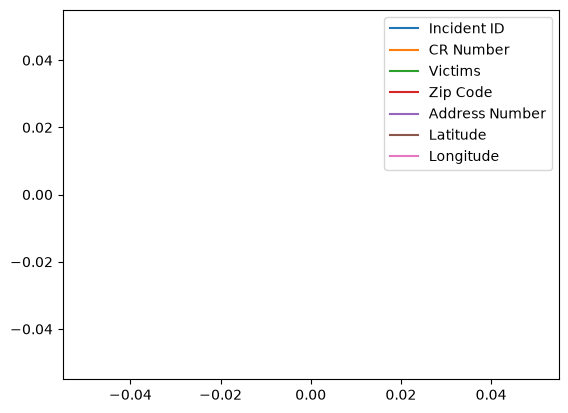

In [16]:
#df_remove_empty_cell = df.copy()
df_all = pd.read_csv("dataset_coursework1-1.csv", low_memory=False)
clean_df = df_all.dropna()
clean_df.plot()
#print(df.to_string())

In [17]:
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
df.sample(100)

,Incident ID,Offense Code,CR Number,Dispatch Date/Time,Start Date/Time,End Date/Time,NIBRS Code,Victims,Crime Name 1,Crime Name 2,Crime Name 3,Police District Name,Block Address,City,State,Zip Code,Agency,Place,Sector,Beat,PRA,Address Number,Street Prefix,Street Name,Street Suffix,Street Type,Latitude,Longitude,Police District Number,Geolocation
427168,201173054,1316,180005185,2018-01-30 19:23:50,2017-12-06 12:00:00,2018-01-27 12:00:00,13C,1,Crime Against Person,Intimidation,ASSAULT - INTIMIDATION (INCLUDES STALKING),MONTGOMERY VILLAGE,100 BLK SUMMER WALK DR,GAITHERSBURG,MD,20878.0,MCPD,Residence - Single Family,P,6P2,450,100.0,NaN,SUMMER WALK,NaN,DR,39.12538,-77.2249,6D,"(39.1254, -77.2249)"
425601,201169080,2610,180000236,2018-01-02 15:18:43,2017-12-16 15:00:00,NaT,26F,1,Crime Against Property,Identity Theft,IDENTITY THEFT,ROCKVILLE,12100 BLK HIDDEN BROOK TER,GAITHERSBURG,MD,20878.0,MCPD,Other/Unknown,B,1B2,556,12100.0,NaN,HIDDEN BROOK,NaN,TER,39.09927,-77.2502,1D,"(39.0993, -77.2502)"
471673,201122240,9101,17009689,NaT,2017-02-23 04:00:00,2017-02-23 00:00:00,90Z,1,Crime Against Society,All Other Offenses,SUDDEN DEATH,BETHESDA,6100 BLK HIGHBORO DR,BETHESDA,MD,20817.0,MCPD,Residence - Single Family,E,2E2,024,6100.0,NaN,HIGHBORO,NaN,DR,38.97498,-77.1235,2D,"(38.975, -77.1235)"
38622,201551916,3532,250050062,2025-11-07 15:16:36,2025-11-07 15:00:00,2025-11-07 16:30:00,35A,1,Crime Against Society,Drug/Narcotic Violations,DRUGS - COCAINE - POSSESS,WHEATON,3000 BLK HEWITT AVE,SILVER SPRING,MD,20906.0,MCPD,Parking Lot - Residential,K,4K1,348,3000.0,NaN,HEWITT,NaN,AVE,0.00000,0.0000,4D,"(0.0, 0.0)"
386118,201204881,2605,180044564,2018-09-06 18:17:43,2018-09-06 18:23:00,NaT,26B,1,Crime Against Property,Credit Card/Automatic Teller Machine Fraud,FRAUD - ILLEGAL USE CREDIT CARDS,MONTGOMERY VILLAGE,1 BLK N SUMMIT AVE,GAITHERSBURG,MD,20877.0,MCPD,Parking Lot - Residential,P,6P3,427,1.0,N,SUMMIT,NaN,AVE,39.14219,-77.1933,6D,"(39.1422, -77.1933)"
20259,201569711,3504,260014299,2026-04-03 16:11:27,2026-04-03 16:11:00,NaT,35A,1,Crime Against Society,Drug/Narcotic Violations,DRUGS - HALLUCINOGEN - POSSESS,SILVER SPRING,NaN,SILVER SPRING,MD,20910.0,MCPD,Street - In vehicle,G,3G2,100,NaN,NaN,GEORGIA,NaN,AVE,39.10125,-77.0769,3D,"(39.1013, -77.0769)"
112303,201478033,1399,240022279,2024-05-11 17:16:20,2024-05-11 17:16:00,NaT,13B,1,Crime Against Person,Simple Assault,ASSAULT - 2ND DEGREE,GERMANTOWN,19900 BLK FREDERICK RD,GERMANTOWN,MD,20876.0,MCPD,Restaurant,M,5M1,471,19900.0,NaN,FREDERICK,NaN,RD,39.18127,-77.2384,5D,"(39.1813, -77.2384)"
410455,201181654,2305,180015718,2018-03-31 23:45:34,2018-03-31 16:30:00,2018-03-31 23:00:00,23F,1,Crime Against Property,Theft From Motor Vehicle,LARCENY - FROM AUTO,ROCKVILLE,200 BLK ROCKVILLE PIK,ROCKVILLE,MD,20850.0,MCPD,Parking Lot - Commercial,A,1A3,275,200.0,NaN,ROCKVILLE,NaN,PIK,39.08519,-77.1482,1D,"(39.0852, -77.1482)"
308150,201279485,1317,200009629,2020-02-26 19:13:29,2020-02-26 19:13:00,NaT,13A,1,Crime Against Person,Aggravated Assault,ATTEMPTED ASSAULT AGGRAVATED POL OFF KNIFE,BETHESDA,6200 BLK ROCKHURST RD,BETHESDA,MD,20817.0,MCPD,Residence - Single Family,E,2E3,194,6200.0,NaN,ROCKHURST,NaN,RD,39.01649,-77.1247,2D,"(39.0165, -77.1247)"
184789,201399535,5404,220048878,2022-11-05 20:59:39,2022-11-05 20:59:00,NaT,90D,1,Crime Against Society,Driving Under the Influence,DRIVING UNDER THE INFLUENCE LIQUOR,GERMANTOWN,12000 BLK S270 X13 TO X11 HWY,GAITHERSBURG,MD,20879.0,MCPD,Street - In vehicle,N,5N1,661,12000.0,NaN,S270 X13 TO X11,NaN,HWY,39.16477,-77.2394,5D,"(39.1648, -77.2394)"


In [18]:
for col in ["Crime Name 1", "Crime Name 2", "Crime Name 3"]:
    print(f"\n--- {col} ---")
    print(df_clean[col].value_counts(dropna=False))


--- Crime Name 1 ---
Crime Name 1
Crime Against Property       228483
Crime Against Society        185456
Crime Against Person          47583
Crime Against Not a Crime      6079
Name: count, dtype: int64

--- Crime Name 2 ---
Crime Name 2
All Other Offenses                             116838
Theft From Motor Vehicle                        38430
Shoplifting                                     33533
Simple Assault                                  33467
Destruction/Damage/Vandalism of Property        27667
Drug/Narcotic Violations                        22483
All other Larceny                               21418
Driving Under the Influence                     19431
Motor Vehicle Theft                             16760
Theft from Building                             16663
Theft of Motor Vehicle Parts or Accessories     13882
Identity Theft                                  13292
Burglary/Breaking and Entering                  13108
False Pretenses/Swindle/Confidence Game         10829
Liqu

In [19]:
crime_groups = (
    df_clean.groupby(["Crime Name 1", "Crime Name 2", "Crime Name 3"], dropna=False)
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)
crime_groups

,Crime Name 1,Crime Name 2,Crime Name 3,Count
159,Crime Against Property,Theft From Motor Vehicle,LARCENY - FROM AUTO,38430
150,Crime Against Property,Shoplifting,LARCENY - SHOPLIFTING,33533
238,Crime Against Society,All Other Offenses,POLICE INFORMATION,32925
59,Crime Against Person,Simple Assault,ASSAULT - 2ND DEGREE,28644
62,Crime Against Property,All other Larceny,LARCENY (DESCRIBE OFFENSE),19387
...,...,...,...,...
49,Crime Against Person,Kidnapping/Abduction,KIDNAP MINOR FOR RANSOM,1
281,Crime Against Society,Drug/Narcotic Violations,DRUGS - AMPHETAMINE - MANUFACTURE,1
38,Crime Against Person,Incest,SEX OFFENSE - INCEST WITH ADULT,1
29,Crime Against Person,Forcible Rape,SEX ASSAULT - SODOMY-MAN-GUN,1


In [20]:
level1 = df_clean.groupby("Crime Name 1").size().reset_index(name="Count").sort_values("Count", ascending=False)
level2 = df_clean.groupby(["Crime Name 1", "Crime Name 2"]).size().reset_index(name="Count").sort_values(["Crime Name 1", "Count"], ascending=[True, False])
 
display(level1)
display(level2)

,Crime Name 1,Count
2,Crime Against Property,228483
3,Crime Against Society,185456
1,Crime Against Person,47583
0,Crime Against Not a Crime,6079


,Crime Name 1,Crime Name 2,Count
1,Crime Against Not a Crime,Runaway,6064
0,Crime Against Not a Crime,Justifiable Homicide,15
12,Crime Against Person,Simple Assault,33467
2,Crime Against Person,Aggravated Assault,6789
4,Crime Against Person,Forcible Rape,3341
3,Crime Against Person,Forcible Fondling,2871
8,Crime Against Person,Intimidation,621
10,Crime Against Person,Murder and Nonnegligent Manslaughter,189
13,Crime Against Person,Statuory Rape,146
9,Crime Against Person,Kidnapping/Abduction,86


In [21]:
with pd.option_context("display.max_rows", None):
    display(crime_groups)

,Crime Name 1,Crime Name 2,Crime Name 3,Count
159,Crime Against Property,Theft From Motor Vehicle,LARCENY - FROM AUTO,38430
150,Crime Against Property,Shoplifting,LARCENY - SHOPLIFTING,33533
238,Crime Against Society,All Other Offenses,POLICE INFORMATION,32925
59,Crime Against Person,Simple Assault,ASSAULT - 2ND DEGREE,28644
62,Crime Against Property,All other Larceny,LARCENY (DESCRIBE OFFENSE),19387
213,Crime Against Society,All Other Offenses,MENTAL ILLNESS - EMERGENCY PETITION,19093
278,Crime Against Society,Driving Under the Influence,DRIVING UNDER THE INFLUENCE LIQUOR,18637
211,Crime Against Society,All Other Offenses,LOST PROPERTY,17833
97,Crime Against Property,Destruction/Damage/Vandalism of Property,DAMAGE PROPERTY - PRIVATE,17234
127,Crime Against Property,Motor Vehicle Theft,AUTO THEFT - VEHICLE THEFT,16087


In [22]:
yearly = df_clean[(df_clean["Start Date/Time"] >= "2016-07-01") &
                  (df_clean["Start Date/Time"] <= "2026-09-10")]
# Year x Crime Category counts
crime_by_year = pd.crosstab(yearly["Year"], yearly["Crime Name 1"])
crime_by_year["Total"] = crime_by_year.sum(axis=1)
crime_by_year["Total_YoY_%"] = crime_by_year["Total"].pct_change().mul(100).round(1)
 
display(crime_by_year)

Crime Name 1,Crime Against Not a Crime,Crime Against Person,Crime Against Property,Crime Against Society,Total,Total_YoY_%
Year,,,,,,
2016,335,2194,11648,11737,25914,NaN
2017,679,4425,22953,23738,51795,99.9
2018,624,4506,20403,24300,49833,-3.8
2019,634,4343,21119,22255,48351,-3.0
2020,499,3903,21180,15812,41394,-14.4
2021,429,4523,21430,15144,41526,0.3
2022,608,4905,22746,16740,44999,8.4
2023,481,5294,25893,11769,43437,-3.5
2024,557,5277,25102,15293,46229,6.4


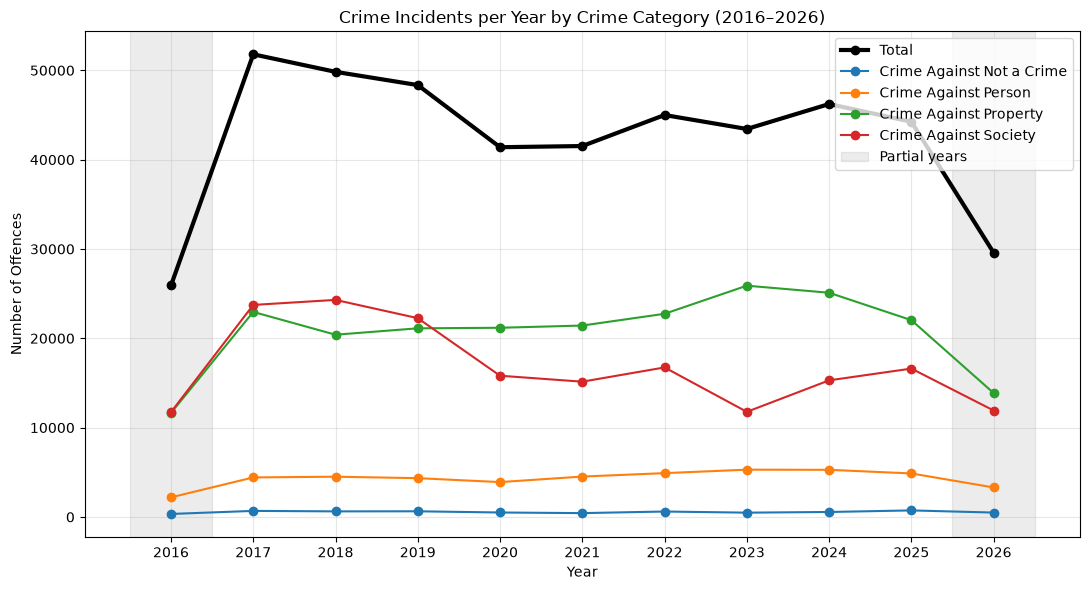

In [23]:
import matplotlib.pyplot as plt
categories = [c for c in crime_by_year.columns if c not in ["Total", "Total_YoY_%"]]
 
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(crime_by_year.index, crime_by_year["Total"], marker="o", linewidth=3, color="black", label="Total")
for cat in categories:
    ax.plot(crime_by_year.index, crime_by_year[cat], marker="o", label=cat)
 
ax.axvspan(2025.5, 2026.5, color="grey", alpha=0.15, label="Partial years")
ax.axvspan(2015.5, 2016.5, color="grey", alpha=0.15)
ax.set_title("Crime Incidents per Year by Crime Category (2016–2026)")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Offences")
ax.set_xticks(crime_by_year.index)
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

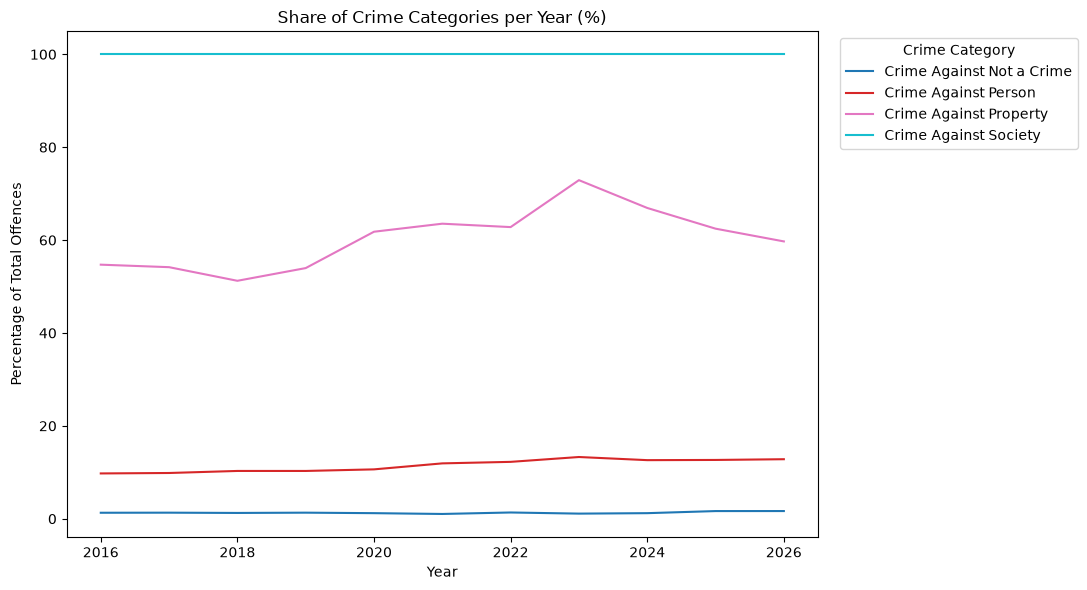

In [24]:
crime_share = crime_by_year[categories].div(crime_by_year["Total"], axis=0).mul(100)
 
crime_share.plot(kind="line", stacked=True, figsize=(11, 6), colormap="tab10")
plt.title("Share of Crime Categories per Year (%)")
plt.xlabel("Year")
plt.ylabel("Percentage of Total Offences")
plt.legend(title="Crime Category", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

In [25]:
crime_long = (
    yearly.groupby(["Year", "Crime Name 1"])
    .size()
    .reset_index(name="Count")
    .sort_values(["Year", "Count"], ascending=[True, False])
)
display(crime_long)

,Year,Crime Name 1,Count
3,2016,Crime Against Society,11737
2,2016,Crime Against Property,11648
1,2016,Crime Against Person,2194
0,2016,Crime Against Not a Crime,335
7,2017,Crime Against Society,23738
6,2017,Crime Against Property,22953
5,2017,Crime Against Person,4425
4,2017,Crime Against Not a Crime,679
11,2018,Crime Against Society,24300
10,2018,Crime Against Property,20403


In [26]:
# Keep only the study period
timed = df_clean[(df_clean["Start Date/Time"] >= "2016-07-01") &
                 (df_clean["Start Date/Time"] <= "2026-09-10 23:59:59")].copy()
 
# Assign time of day from Hour
timed["Time_Period"] = pd.cut(
    timed["Hour"],
    bins=[-1, 5, 11, 17, 23],
    labels=["Night", "Morning", "Afternoon", "Evening"]
)
timed["Day_Night"] = np.where(timed["Time_Period"].isin(["Morning", "Afternoon"]), "Daytime", "Nighttime")
 
# 1. Daytime vs Nighttime totals
day_night = timed["Day_Night"].value_counts().rename("Count").to_frame()
day_night["Percent"] = (day_night["Count"] / day_night["Count"].sum() * 100).round(2)
display(day_night)
 
# 2. Breakdown by the four time periods
period_order = ["Morning", "Afternoon", "Evening", "Night"]
period_counts = timed["Time_Period"].value_counts().reindex(period_order).rename("Count").to_frame()
period_counts["Group"] = ["Daytime", "Daytime", "Nighttime", "Nighttime"]
period_counts["Percent"] = (period_counts["Count"] / period_counts["Count"].sum() * 100).round(2)
display(period_counts)

,Count,Percent
Day_Night,,
Daytime,249160,53.31
Nighttime,218224,46.69


,Count,Group,Percent
Time_Period,,,
Morning,88056,Daytime,18.84
Afternoon,161104,Daytime,34.47
Evening,143241,Nighttime,30.65
Night,74983,Nighttime,16.04


In [27]:
display(pd.crosstab(timed["Year"], timed["Day_Night"], margins=True, margins_name="Total"))

Day_Night,Daytime,Nighttime,Total
Year,,,
2016,12275,13639,25914
2017,25405,26390,51795
2018,25244,24589,49833
2019,24611,23740,48351
2020,21934,19460,41394
2021,22412,19114,41526
2022,24403,20596,44999
2023,23842,19595,43437
2024,26101,20128,46229


In [28]:
# Keep only the study period
dist = df_clean[(df_clean["Start Date/Time"] >= "2016-07-01") &
                (df_clean["Start Date/Time"] <= "2026-09-10")]
 
# 1. Count of each crime category per district
district_counts = pd.crosstab(dist["Police District Name"], dist["Crime Name 1"],
                              margins=True, margins_name="Total")
district_counts = district_counts.sort_values("Total", ascending=False)
display(district_counts)
 
# 2. Crime type mix within each district (row %)
district_mix = pd.crosstab(dist["Police District Name"], dist["Crime Name 1"],
                           normalize="index").mul(100).round(1)
display(district_mix)
 
# 3. Each district's share of the county total for each crime type (column %)
district_share = pd.crosstab(dist["Police District Name"], dist["Crime Name 1"],
                             normalize="columns").mul(100).round(1)
display(district_share)

top_offences = (
    dist.groupby(["Police District Name", "Crime Name 1", "Crime Name 2"])
    .size()
    .reset_index(name="Count")
    .sort_values(["Police District Name", "Count"], ascending=[True, False])
    .groupby("Police District Name")
    .head(5)
)
display(top_offences)


top1 = (
    dist.groupby(["Police District Name", "Crime Name 2"]).size().reset_index(name="Count")
    .sort_values("Count", ascending=False)
    .drop_duplicates("Police District Name")
    .set_index("Police District Name")
)
top1["Pct_of_District"] = (top1["Count"] / dist["Police District Name"].value_counts() * 100).round(1)
display(top1.sort_values("Count", ascending=False))

Crime Name 1,Crime Against Not a Crime,Crime Against Person,Crime Against Property,Crime Against Society,Total
Police District Name,,,,,
Total,6056,47378,227687,184767,465888
SILVER SPRING,970,9656,49314,36791,96731
WHEATON,1402,8770,39699,36006,85877
MONTGOMERY VILLAGE,1385,9715,34436,32662,78198
BETHESDA,830,5099,39398,22748,68075
ROCKVILLE,452,5541,27946,30173,64112
GERMANTOWN,938,7578,28897,21864,59277
TAKOMA PARK,79,1016,7988,4521,13604
OTHER,0,3,9,2,14


Crime Name 1,Crime Against Not a Crime,Crime Against Person,Crime Against Property,Crime Against Society
Police District Name,,,,
BETHESDA,1.2,7.5,57.9,33.4
GERMANTOWN,1.6,12.8,48.7,36.9
MONTGOMERY VILLAGE,1.8,12.4,44.0,41.8
OTHER,0.0,21.4,64.3,14.3
ROCKVILLE,0.7,8.6,43.6,47.1
SILVER SPRING,1.0,10.0,51.0,38.0
TAKOMA PARK,0.6,7.5,58.7,33.2
WHEATON,1.6,10.2,46.2,41.9


Crime Name 1,Crime Against Not a Crime,Crime Against Person,Crime Against Property,Crime Against Society
Police District Name,,,,
BETHESDA,13.7,10.8,17.3,12.3
GERMANTOWN,15.5,16.0,12.7,11.8
MONTGOMERY VILLAGE,22.9,20.5,15.1,17.7
OTHER,0.0,0.0,0.0,0.0
ROCKVILLE,7.5,11.7,12.3,16.3
SILVER SPRING,16.0,20.4,21.7,19.9
TAKOMA PARK,1.3,2.1,3.5,2.4
WHEATON,23.2,18.5,17.4,19.5


,Police District Name,Crime Name 1,Crime Name 2,Count
36,BETHESDA,Crime Against Society,All Other Offenses,17011
31,BETHESDA,Crime Against Property,Theft From Motor Vehicle,7028
29,BETHESDA,Crime Against Property,Shoplifting,5534
10,BETHESDA,Crime Against Person,Simple Assault,3825
12,BETHESDA,Crime Against Property,All other Larceny,3729
86,GERMANTOWN,Crime Against Society,All Other Offenses,14300
79,GERMANTOWN,Crime Against Property,Shoplifting,6576
60,GERMANTOWN,Crime Against Person,Simple Assault,5512
81,GERMANTOWN,Crime Against Property,Theft From Motor Vehicle,4307
67,GERMANTOWN,Crime Against Property,Destruction/Damage/Vandalism of Property,3574


,Crime Name 2,Count,Pct_of_District
Police District Name,,,
ROCKVILLE,All Other Offenses,21256,33.2
SILVER SPRING,All Other Offenses,20457,21.1
WHEATON,All Other Offenses,20333,23.7
MONTGOMERY VILLAGE,All Other Offenses,19643,25.1
BETHESDA,All Other Offenses,17011,25.0
GERMANTOWN,All Other Offenses,14300,24.1
TAKOMA PARK,All Other Offenses,3315,24.4
OTHER,All Other Offenses,2,14.3


In [29]:
zcta_pop = pd.read_csv("ext-data/zcta_population.csv")
zcta_pop1 = pd.DataFrame(zcta_pop)
zcta_pop1



,Label (Grouping),ZCTA5 19973!!Estimate,ZCTA5 19973!!Margin of Error,ZCTA5 20601!!Estimate,ZCTA5 20601!!Margin of Error,ZCTA5 20602!!Estimate,ZCTA5 20602!!Margin of Error,ZCTA5 20603!!Estimate,ZCTA5 20603!!Margin of Error,ZCTA5 20606!!Estimate,ZCTA5 20606!!Margin of Error,ZCTA5 20607!!Estimate,ZCTA5 20607!!Margin of Error,ZCTA5 20608!!Estimate,ZCTA5 20608!!Margin of Error,ZCTA5 20609!!Estimate,ZCTA5 20609!!Margin of Error,ZCTA5 20611!!Estimate,ZCTA5 20611!!Margin of Error,ZCTA5 20612!!Estimate,ZCTA5 20612!!Margin of Error,ZCTA5 20613!!Estimate,ZCTA5 20613!!Margin of Error,ZCTA5 20615!!Estimate,ZCTA5 20615!!Margin of Error,ZCTA5 20616!!Estimate,ZCTA5 20616!!Margin of Error,ZCTA5 20617!!Estimate,ZCTA5 20617!!Margin of Error,ZCTA5 20618!!Estimate,ZCTA5 20618!!Margin of Error,ZCTA5 20619!!Estimate,ZCTA5 20619!!Margin of Error,ZCTA5 20620!!Estimate,ZCTA5 20620!!Margin of Error,ZCTA5 20621!!Estimate,ZCTA5 20621!!Margin of Error,ZCTA5 20622!!Estimate,ZCTA5 20622!!Margin of Error,ZCTA5 20623!!Estimate,ZCTA5 20623!!Margin of Error,ZCTA5 20624!!Estimate,ZCTA5 20624!!Margin of Error,ZCTA5 20625!!Estimate,ZCTA5 20625!!Margin of Error,ZCTA5 20626!!Estimate,ZCTA5 20626!!Margin of Error,ZCTA5 20628!!Estimate,ZCTA5 20628!!Margin of Error,ZCTA5 20629!!Estimate,ZCTA5 20629!!Margin of Error,ZCTA5 20630!!Estimate,ZCTA5 20630!!Margin of Error,ZCTA5 20632!!Estimate,ZCTA5 20632!!Margin of Error,ZCTA5 20634!!Estimate,ZCTA5 20634!!Margin of Error,ZCTA5 20636!!Estimate,ZCTA5 20636!!Margin of Error,ZCTA5 20637!!Estimate,ZCTA5 20637!!Margin of Error,ZCTA5 20639!!Estimate,ZCTA5 20639!!Margin of Error,ZCTA5 20640!!Estimate,ZCTA5 20640!!Margin of Error,ZCTA5 20645!!Estimate,ZCTA5 20645!!Margin of Error,ZCTA5 20646!!Estimate,ZCTA5 20646!!Margin of Error,ZCTA5 20650!!Estimate,ZCTA5 20650!!Margin of Error,ZCTA5 20653!!Estimate,ZCTA5 20653!!Margin of Error,ZCTA5 20656!!Estimate,ZCTA5 20656!!Margin of Error,ZCTA5 20657!!Estimate,ZCTA5 20657!!Margin of Error,ZCTA5 20658!!Estimate,ZCTA5 20658!!Margin of Error,ZCTA5 20659!!Estimate,ZCTA5 20659!!Margin of Error,ZCTA5 20660!!Estimate,ZCTA5 20660!!Margin of Error,ZCTA5 20661!!Estimate,ZCTA5 20661!!Margin of Error,ZCTA5 20662!!Estimate,ZCTA5 20662!!Margin of Error,ZCTA5 20664!!Estimate,ZCTA5 20664!!Margin of Error,ZCTA5 20667!!Estimate,ZCTA5 20667!!Margin of Error,ZCTA5 20670!!Estimate,ZCTA5 20670!!Margin of Error,ZCTA5 20674!!Estimate,ZCTA5 20674!!Margin of Error,ZCTA5 20675!!Estimate,ZCTA5 20675!!Margin of Error,ZCTA5 20676!!Estimate,ZCTA5 20676!!Margin of Error,ZCTA5 20677!!Estimate,ZCTA5 20677!!Margin of Error,ZCTA5 20678!!Estimate,ZCTA5 20678!!Margin of Error,ZCTA5 20680!!Estimate,ZCTA5 20680!!Margin of Error,ZCTA5 20684!!Estimate,ZCTA5 20684!!Margin of Error,ZCTA5 20685!!Estimate,ZCTA5 20685!!Margin of Error,ZCTA5 20686!!Estimate,ZCTA5 20686!!Margin of Error,ZCTA5 20687!!Estimate,ZCTA5 20687!!Margin of Error,ZCTA5 20688!!Estimate,ZCTA5 20688!!Margin of Error,ZCTA5 20689!!Estimate,ZCTA5 20689!!Margin of Error,ZCTA5 20690!!Estimate,ZCTA5 20690!!Margin of Error,ZCTA5 20692!!Estimate,ZCTA5 20692!!Margin of Error,ZCTA5 20693!!Estimate,ZCTA5 20693!!Margin of Error,ZCTA5 20695!!Estimate,ZCTA5 20695!!Margin of Error,ZCTA5 20701!!Estimate,ZCTA5 20701!!Margin of Error,ZCTA5 20705!!Estimate,ZCTA5 20705!!Margin of Error,ZCTA5 20706!!Estimate,ZCTA5 20706!!Margin of Error,ZCTA5 20707!!Estimate,ZCTA5 20707!!Margin of Error,ZCTA5 20708!!Estimate,ZCTA5 20708!!Margin of Error,ZCTA5 20710!!Estimate,ZCTA5 20710!!Margin of Error,ZCTA5 20711!!Estimate,ZCTA5 20711!!Margin of Error,ZCTA5 20712!!Estimate,ZCTA5 20712!!Margin of Error,ZCTA5 20714!!Estimate,ZCTA5 20714!!Margin of Error,ZCTA5 20715!!Estimate,ZCTA5 20715!!Margin of Error,ZCTA5 20716!!Estimate,ZCTA5 20716!!Margin of Error,ZCTA5 20720!!Estimate,ZCTA5 20720!!Margin of Error,ZCTA5 20721!!Estimate,ZCTA5 20721!!Margin of Error,ZCTA5 20722!!Estimate,ZCTA5 20722!!Margin of Error,ZCTA5 20723!!Estimate,ZCTA5 20723!!Margin of Error,ZCTA5 20724!!Estimate,ZCTA5 20724!!Margin of Error,ZCTA

In [30]:
#Motor Vehicle Thefts Cleanup.
mvt = df_clean[(df_clean["Crime Name 2"] == "Motor Vehicle Theft") &
               (df_clean["Start Date/Time"] >= "2016-07-01") &
               (df_clean["Start Date/Time"] <= "2026-09-10 23:59:59")].copy()
 
print(f"Motor vehicle thefts: {len(mvt):,}")

Motor vehicle thefts: 16,750


In [31]:
def concentration(col, top=15):
    t = mvt[col].value_counts().rename("Count").to_frame()
    t["Percent"] = (t["Count"] / t["Count"].sum() * 100).round(2)
    t["Cumulative_%"] = t["Percent"].cumsum().round(2)
    return t.head(top)
 
display(concentration("Police District Name"))
display(concentration("City"))
display(concentration("Beat"))
display(concentration("Place"))

,Count,Percent,Cumulative_%
Police District Name,,,
SILVER SPRING,5184,31.09,31.09
WHEATON,3071,18.42,49.51
MONTGOMERY VILLAGE,2749,16.48,65.99
BETHESDA,2001,12.00,77.99
ROCKVILLE,1634,9.80,87.79
GERMANTOWN,1535,9.20,96.99
TAKOMA PARK,500,3.00,99.99
OTHER,2,0.01,100.00


,Count,Percent,Cumulative_%
City,,,
SILVER SPRING,7439,44.41,44.41
GAITHERSBURG,2085,12.45,56.86
ROCKVILLE,2036,12.16,69.02
GERMANTOWN,1232,7.36,76.38
BETHESDA,831,4.96,81.34
TAKOMA PARK,627,3.74,85.08
MONTGOMERY VILLAGE,626,3.74,88.82
BURTONSVILLE,382,2.28,91.10
CHEVY CHASE,297,1.77,92.87


,Count,Percent,Cumulative_%
Beat,,,
3G1,1321,7.89,7.89
3I2,1226,7.32,15.21
3I1,1159,6.92,22.13
4K1,781,4.66,26.79
4L1,648,3.87,30.66
6P1,529,3.16,33.82
6R2,513,3.06,36.88
5N1,510,3.04,39.92
4L2,504,3.01,42.93


,Count,Percent,Cumulative_%
Place,,,
Parking Lot - Residential,5462,32.61,32.61
Street - Residential,3890,23.22,55.83
Residence - Driveway,1599,9.55,65.38
Parking Lot - Commercial,1102,6.58,71.96
Parking Garage - Residential,646,3.86,75.82
Street - Commercial,455,2.72,78.54
Auto Dealership,381,2.27,80.81
Residence - Single Family,357,2.13,82.94
Street - Other,308,1.84,84.78


In [32]:
geo = mvt.dropna(subset=["Latitude", "Longitude"]).copy()
geo["Lat_Grid"] = geo["Latitude"].round(2)
geo["Lon_Grid"] = geo["Longitude"].round(2)
 
hotspots = (
    geo.groupby(["Lat_Grid", "Lon_Grid"])
    .agg(Count=("Incident ID", "count"),
         Main_City=("City", lambda s: s.mode().iat[0]),
         Main_District=("Police District Name", lambda s: s.mode().iat[0]))
    .sort_values("Count", ascending=False)
    .reset_index()
)
hotspots["Percent"] = (hotspots["Count"] / len(geo) * 100).round(2)
display(hotspots.head(20))

,Lat_Grid,Lon_Grid,Count,Main_City,Main_District,Percent
0,38.99,-77.03,377,SILVER SPRING,SILVER SPRING,2.48
1,39.08,-76.94,310,SILVER SPRING,SILVER SPRING,2.04
2,39.04,-76.99,308,SILVER SPRING,SILVER SPRING,2.03
3,39.00,-77.03,254,SILVER SPRING,SILVER SPRING,1.67
4,38.99,-77.02,234,SILVER SPRING,SILVER SPRING,1.54
5,39.04,-77.05,215,SILVER SPRING,WHEATON,1.42
6,39.09,-77.07,175,SILVER SPRING,WHEATON,1.15
7,39.00,-77.00,175,SILVER SPRING,SILVER SPRING,1.15
8,39.05,-76.98,168,SILVER SPRING,SILVER SPRING,1.11
9,39.06,-77.05,160,SILVER SPRING,WHEATON,1.05


In [33]:
#Motor Theft By Year
mvt_full = mvt[mvt["Year"].between(2017, 2025)]
 
district_year = pd.crosstab(mvt_full["Police District Name"], mvt_full["Year"],
                            margins=True, margins_name="Total")
display(district_year)

Year,2017,2018,2019,2020,2021,2022,2023,2024,2025,Total
Police District Name,,,,,,,,,,
BETHESDA,94,97,104,149,230,242,311,245,280,1752
GERMANTOWN,82,61,65,113,127,99,290,241,197,1275
MONTGOMERY VILLAGE,135,138,144,181,193,197,520,454,298,2260
OTHER,0,0,1,0,0,0,1,0,0,2
ROCKVILLE,85,69,91,96,147,159,242,318,198,1405
SILVER SPRING,269,255,271,338,407,372,1102,827,711,4552
TAKOMA PARK,32,30,22,39,35,47,100,71,73,449
WHEATON,161,114,142,147,194,263,598,575,446,2640
Total,858,764,840,1063,1333,1379,3164,2731,2203,14335


In [34]:
district_share = pd.crosstab(mvt_full["Police District Name"], mvt_full["Year"],
                             normalize="columns").mul(100).round(1)
display(district_share)

Year,2017,2018,2019,2020,2021,2022,2023,2024,2025
Police District Name,,,,,,,,,
BETHESDA,11.0,12.7,12.4,14.0,17.3,17.5,9.8,9.0,12.7
GERMANTOWN,9.6,8.0,7.7,10.6,9.5,7.2,9.2,8.8,8.9
MONTGOMERY VILLAGE,15.7,18.1,17.1,17.0,14.5,14.3,16.4,16.6,13.5
OTHER,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.0,0.0
ROCKVILLE,9.9,9.0,10.8,9.0,11.0,11.5,7.6,11.6,9.0
SILVER SPRING,31.4,33.4,32.3,31.8,30.5,27.0,34.8,30.3,32.3
TAKOMA PARK,3.7,3.9,2.6,3.7,2.6,3.4,3.2,2.6,3.3
WHEATON,18.8,14.9,16.9,13.8,14.6,19.1,18.9,21.1,20.2


In [35]:
district_rank = pd.crosstab(mvt_full["Police District Name"], mvt_full["Year"]) \
                  .rank(ascending=False, method="min").astype(int)
display(district_rank)

Year,2017,2018,2019,2020,2021,2022,2023,2024,2025
Police District Name,,,,,,,,,
BETHESDA,4,4,4,3,2,3,4,5,4
GERMANTOWN,6,6,6,5,6,6,5,6,6
MONTGOMERY VILLAGE,3,2,2,2,4,4,3,3,3
OTHER,8,8,8,8,8,8,8,8,8
ROCKVILLE,5,5,5,6,5,5,6,4,5
SILVER SPRING,1,1,1,1,1,1,1,1,1
TAKOMA PARK,7,7,7,7,7,7,7,7,7
WHEATON,2,3,3,4,3,2,2,2,2


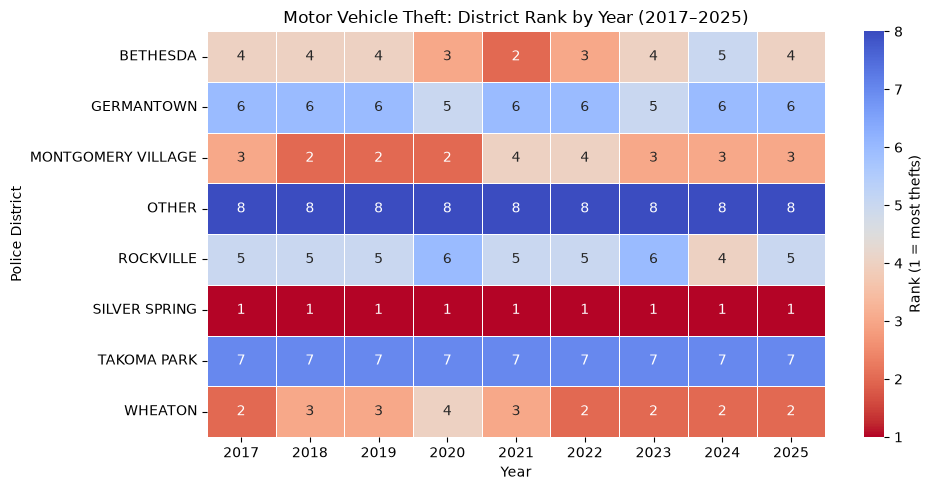

In [36]:
#%pip install seaborn

import matplotlib.pyplot as plt
import seaborn as sns
 
district_rank = pd.crosstab(mvt_full["Police District Name"], mvt_full["Year"]) \
                  .rank(ascending=False, method="min").astype(int)
 
plt.figure(figsize=(10, 5))
sns.heatmap(district_rank, annot=True, fmt="d", cmap="coolwarm_r",
            linewidths=0.5, cbar_kws={"label": "Rank (1 = most thefts)"})
plt.title("Motor Vehicle Theft: District Rank by Year (2017–2025)")
plt.xlabel("Year")
plt.ylabel("Police District")
plt.tight_layout()
plt.show()

##Which types of offences most frequently occur together within the same recorded incident?

In [37]:
# How many incidents contain more than one distinct offence?
multi_check = df.groupby("Incident ID")["Offense Code"].nunique()
print(f"Incidents with >1 distinct offence: {(multi_check > 1).sum():,}")
print(f"Rows that are exact Incident+Offence duplicates: {df.duplicated(subset=['Incident ID', 'Offense Code']).sum():,}")

Incidents with >1 distinct offence: 33,749
Rows that are exact Incident+Offence duplicates: 0


In [38]:
from itertools import combinations
from collections import Counter
 
offences = df.drop_duplicates(subset=["Incident ID", "Offense Code"])
offences = offences[(offences["Start Date/Time"] >= "2016-07-01") &
                    (offences["Start Date/Time"] <= "2026-09-10 23:59:59")]
 
# How many offences are recorded per incident?
offences_per_incident = offences.groupby("Incident ID").size().value_counts().sort_index()
offences_per_incident = offences_per_incident.rename("Incidents").to_frame()
offences_per_incident.index.name = "Offences in incident"
offences_per_incident["Percent"] = (offences_per_incident["Incidents"] / offences_per_incident["Incidents"].sum() * 100).round(2)
display(offences_per_incident)

,Incidents,Percent
Offences in incident,,
1,433644,92.78
2,28596,6.12
3,3933,0.84
4,918,0.20
5,219,0.05
6,50,0.01
7,18,0.00
8,4,0.00
9,2,0.00


In [39]:
# Distinct offence types per incident (Crime Name 2 level)
per_incident = offences.groupby("Incident ID")["Crime Name 2"].apply(lambda s: sorted(set(s.dropna())))
n_incidents = len(per_incident)
 
# How many incidents each offence type appears in
single_counts = Counter(o for offs in per_incident for o in offs)
 
# Count every pair of offences that appear in the same incident
pair_counts = Counter(p for offs in per_incident if len(offs) > 1 for p in combinations(offs, 2))
 
pairs = pd.DataFrame([(a, b, n) for (a, b), n in pair_counts.items()],
                     columns=["Offence A", "Offence B", "Incidents_Together"])
 
pairs["Support_%"] = (pairs["Incidents_Together"] / n_incidents * 100).round(3)
pairs["Pct_of_A_with_B"] = (pairs["Incidents_Together"] / pairs["Offence A"].map(single_counts) * 100).round(1)
pairs["Pct_of_B_with_A"] = (pairs["Incidents_Together"] / pairs["Offence B"].map(single_counts) * 100).round(1)
pairs["Lift"] = (pairs["Incidents_Together"] * n_incidents /
                 (pairs["Offence A"].map(single_counts) * pairs["Offence B"].map(single_counts))).round(2)
 
pairs = pairs.sort_values("Incidents_Together", ascending=False).reset_index(drop=True)
display(pairs.head(20))

,Offence A,Offence B,Incidents_Together,Support_%,Pct_of_A_with_B,Pct_of_B_with_A,Lift
0,Destruction/Damage/Vandalism of Property,Theft From Motor Vehicle,2664,0.570,8.3,6.5,0.94
1,All Other Offenses,Simple Assault,1732,0.371,1.4,4.7,0.18
2,Drug Equipment Violations,Drug/Narcotic Violations,1724,0.369,52.7,6.8,9.66
3,Destruction/Damage/Vandalism of Property,Simple Assault,1594,0.341,5.0,4.3,0.63
4,Credit Card/Automatic Teller Machine Fraud,Theft From Motor Vehicle,1184,0.253,14.3,2.9,1.62
5,Burglary/Breaking and Entering,Destruction/Damage/Vandalism of Property,1145,0.245,8.0,3.6,1.16
6,Disorderly Conduct,Simple Assault,1092,0.234,14.0,3.0,1.77
7,All Other Offenses,Drug/Narcotic Violations,1062,0.227,0.9,4.2,0.16
8,Motor Vehicle Theft,Theft From Motor Vehicle,1034,0.221,5.8,2.5,0.65
9,Drug/Narcotic Violations,Weapon Law Violations,901,0.193,3.5,22.0,4.04


In [40]:
display(pairs[pairs["Incidents_Together"] >= 50].sort_values("Lift", ascending=False).head(20))

,Offence A,Offence B,Incidents_Together,Support_%,Pct_of_A_with_B,Pct_of_B_with_A,Lift
109,Assisting or Promoting Prostitution,"Human Trafficking, Commercial Sex Acts",60,0.013,39.0,63.8,1937.21
97,"Human Trafficking, Commercial Sex Acts",Prostitution,74,0.016,78.7,25.6,1273.15
72,Assisting or Promoting Prostitution,Prostitution,112,0.024,72.7,38.8,1176.18
2,Drug Equipment Violations,Drug/Narcotic Violations,1724,0.369,52.7,6.8,9.66
67,Credit Card/Automatic Teller Machine Fraud,Pocket/picking,128,0.027,1.5,11.4,6.43
20,Disorderly Conduct,Trespass of Real Property,544,0.116,7.0,8.6,5.16
62,Drug Equipment Violations,Weapon Law Violations,140,0.030,4.3,3.4,4.89
9,Drug/Narcotic Violations,Weapon Law Violations,901,0.193,3.5,22.0,4.04
93,Forcible Fondling,Forcible Rape,76,0.016,2.5,2.2,3.36
11,Credit Card/Automatic Teller Machine Fraud,Theft from Building,870,0.186,10.5,4.9,2.78


In [41]:
per_incident_c1 = offences.groupby("Incident ID")["Crime Name 1"].apply(lambda s: sorted(set(s.dropna())))
pairs_c1 = Counter(p for offs in per_incident_c1 if len(offs) > 1 for p in combinations(offs, 2))
display(pd.DataFrame(pairs_c1.most_common(), columns=["Category Pair", "Incidents_Together"]))

,Category Pair,Incidents_Together
0,"(Crime Against Property, Crime Against Society)",4904
1,"(Crime Against Person, Crime Against Property)",4361
2,"(Crime Against Person, Crime Against Society)",4113
3,"(Crime Against Not a Crime, Crime Against Soci...",118
4,"(Crime Against Not a Crime, Crime Against Person)",18
5,"(Crime Against Not a Crime, Crime Against Prop...",12


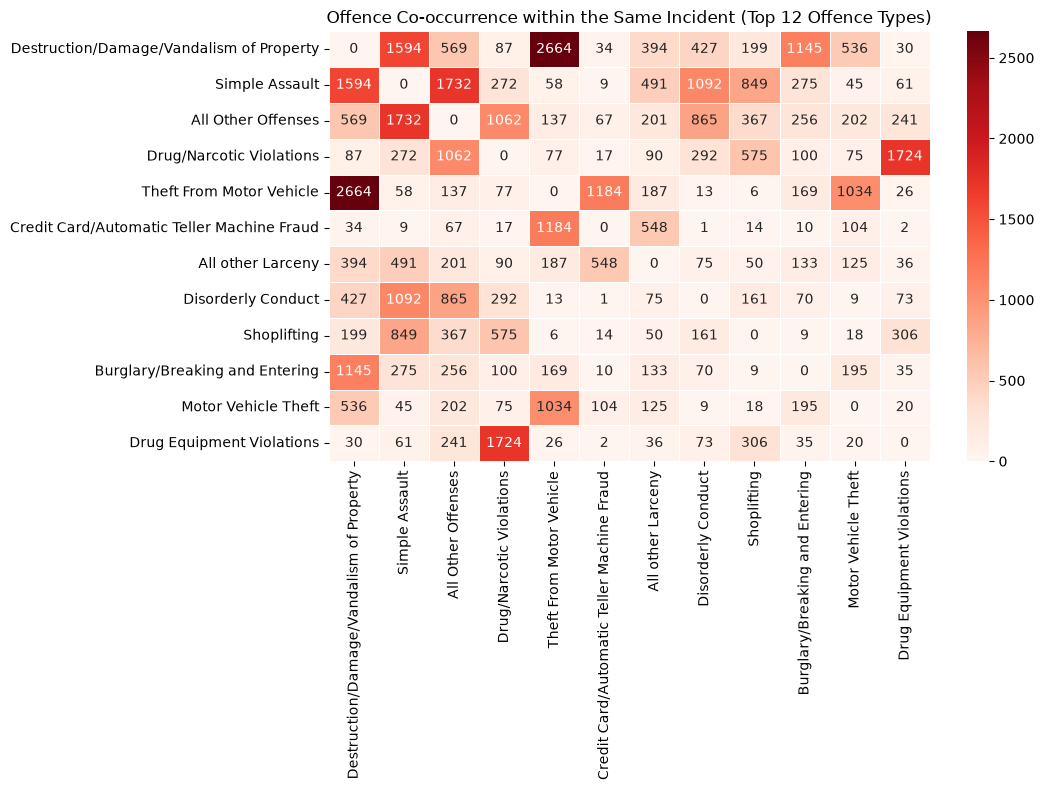

In [42]:
import seaborn as sns
import matplotlib.pyplot as plt
 
top_offences = [o for o, _ in Counter(o for offs in per_incident if len(offs) > 1 for o in offs).most_common(12)]
 
matrix = pd.DataFrame(0, index=top_offences, columns=top_offences)
for (a, b), n in pair_counts.items():
    if a in top_offences and b in top_offences:
        matrix.loc[a, b] = n
        matrix.loc[b, a] = n
 
plt.figure(figsize=(11, 8))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Reds", linewidths=0.5)
plt.title("Offence Co-occurrence within the Same Incident (Top 12 Offence Types)")
plt.tight_layout()
plt.show()

### Are certain crime types more likely to have missing dispatch timestamps than others?

In [43]:
disp = df_clean[(df_clean["Start Date/Time"] >= "2016-07-01") &
                (df_clean["Start Date/Time"] <= "2026-09-10 23:59:59")].copy()
disp["Dispatch_Missing"] = disp["Dispatch Date/Time"].isna()
 
overall_rate = disp["Dispatch_Missing"].mean() * 100
print(f"Overall missing dispatch rate: {overall_rate:.2f}%")
 
def missing_by(col, min_n=0):
    t = disp.groupby(col)["Dispatch_Missing"].agg(Total="size", Missing="sum")
    t["Missing_%"] = (t["Missing"] / t["Total"] * 100).round(2)
    t["Vs_Overall"] = (t["Missing_%"] / overall_rate).round(2)
    return t[t["Total"] >= min_n].sort_values("Missing_%", ascending=False)
 
display(missing_by("Crime Name 1"))

Overall missing dispatch rate: 14.57%


,Total,Missing,Missing_%,Vs_Overall
Crime Name 1,,,,
Crime Against Society,185354,32345,17.45,1.20
Crime Against Property,228410,29438,12.89,0.88
Crime Against Person,47549,5662,11.91,0.82
Crime Against Not a Crime,6071,667,10.99,0.75


In [44]:
offence_totals = df_clean["Crime Name 2"].value_counts().rename("Count").to_frame()
offence_totals["Percent"] = (offence_totals["Count"] / offence_totals["Count"].sum() * 100).round(2)

with pd.option_context("display.max_rows", None):
    display(offence_totals)

print(f"Total offences: {offence_totals['Count'].sum():,} across {len(offence_totals)} offence types")

,Count,Percent
Crime Name 2,,
All Other Offenses,116838,24.99
Theft From Motor Vehicle,38430,8.22
Shoplifting,33533,7.17
Simple Assault,33467,7.16
Destruction/Damage/Vandalism of Property,27667,5.92
Drug/Narcotic Violations,22483,4.81
All other Larceny,21418,4.58
Driving Under the Influence,19431,4.16
Motor Vehicle Theft,16760,3.58


Total offences: 467,601 across 53 offence types


In [ ]:
mvt_like = missing_by("Crime Name 2", min_n=100)   # ignore very rare offences
display(mvt_like.head(25))   # most often missing
display(mvt_like.tail(25))   # least often missing

,Total,Missing,Missing_%,Vs_Overall
Crime Name 2,,,,
Pornography/Obscene Material,1201,865,72.02,4.94
Impersonation,1816,939,51.71,3.55
Animal Cruelty,143,70,48.95,3.36
Prostitution,197,88,44.67,3.07
Liquor Law Violations,7361,2084,28.31,1.94
Statuory Rape,145,38,26.21,1.80
Arson,503,127,25.25,1.73
Forcible Rape,3341,796,23.83,1.64
Forcible Fondling,2870,665,23.17,1.59


,Total,Missing,Missing_%,Vs_Overall
Crime Name 2,,,,
Counterfeiting/Forgery,4110,633,15.40,1.06
Embezzlement,855,128,14.97,1.03
All Other Offenses,116757,17397,14.90,1.02
Theft from Building,16659,2462,14.78,1.01
Theft From Motor Vehicle,38423,5590,14.55,1.00
All other Larceny,21414,3089,14.43,0.99
Pocket/picking,1052,151,14.35,0.98
Credit Card/Automatic Teller Machine Fraud,6738,953,14.14,0.97
False Pretenses/Swindle/Confidence Game,10828,1508,13.93,0.96


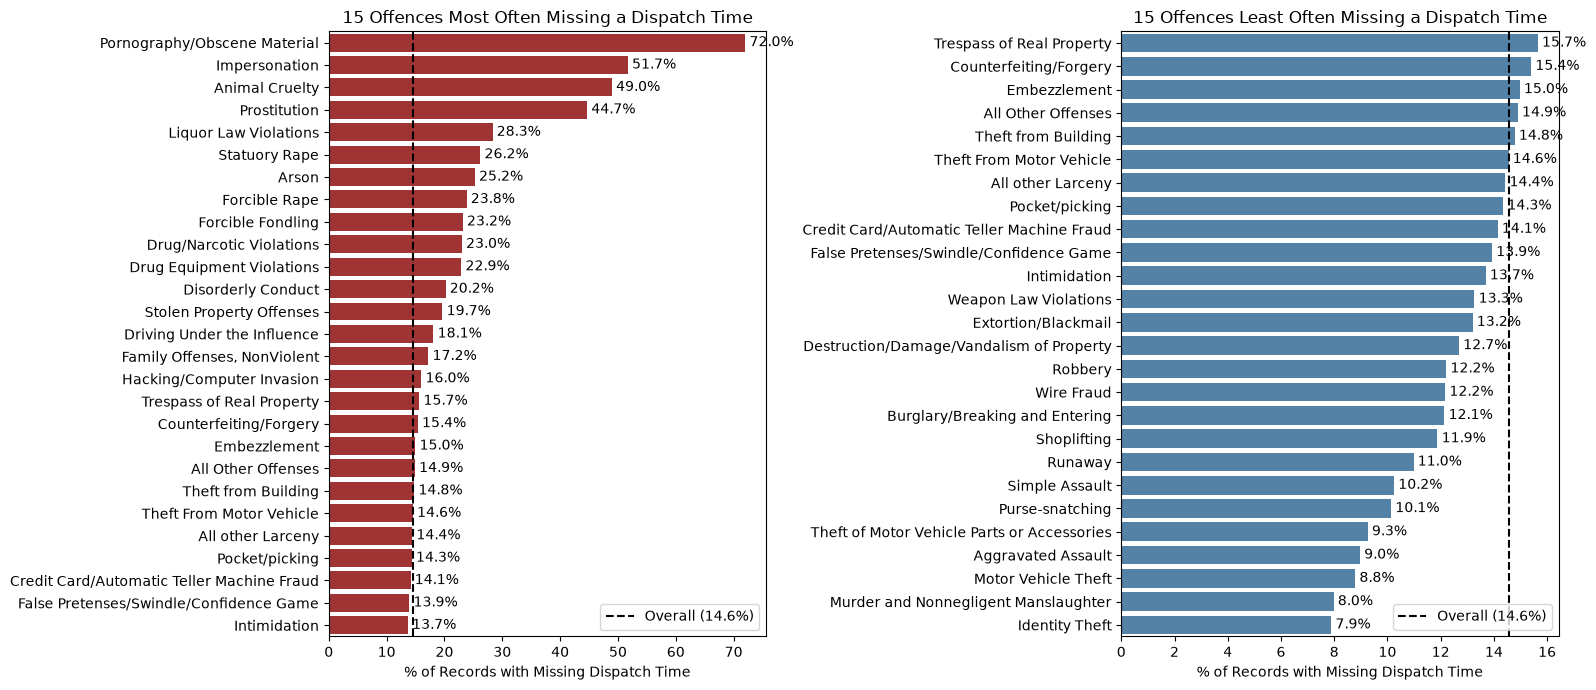

In [46]:
import matplotlib.pyplot as plt
import seaborn as sns
 
offence_missing = missing_by("Crime Name 2", min_n=100)
most_missing = offence_missing.head(27).reset_index()
least_missing = offence_missing.tail(26).reset_index()
 
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
 
sns.barplot(data=most_missing, x="Missing_%", y="Crime Name 2", ax=axes[0], color="firebrick")
axes[0].set_title("15 Offences Most Often Missing a Dispatch Time")
 
sns.barplot(data=least_missing, x="Missing_%", y="Crime Name 2", ax=axes[1], color="steelblue")
axes[1].set_title("15 Offences Least Often Missing a Dispatch Time")
 
for ax in axes:
    ax.axvline(overall_rate, color="black", linestyle="--", label=f"Overall ({overall_rate:.1f}%)")
    ax.set_xlabel("% of Records with Missing Dispatch Time")
    ax.set_ylabel("")
    ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
    ax.legend(loc="lower right")
 
plt.tight_layout()
plt.show()

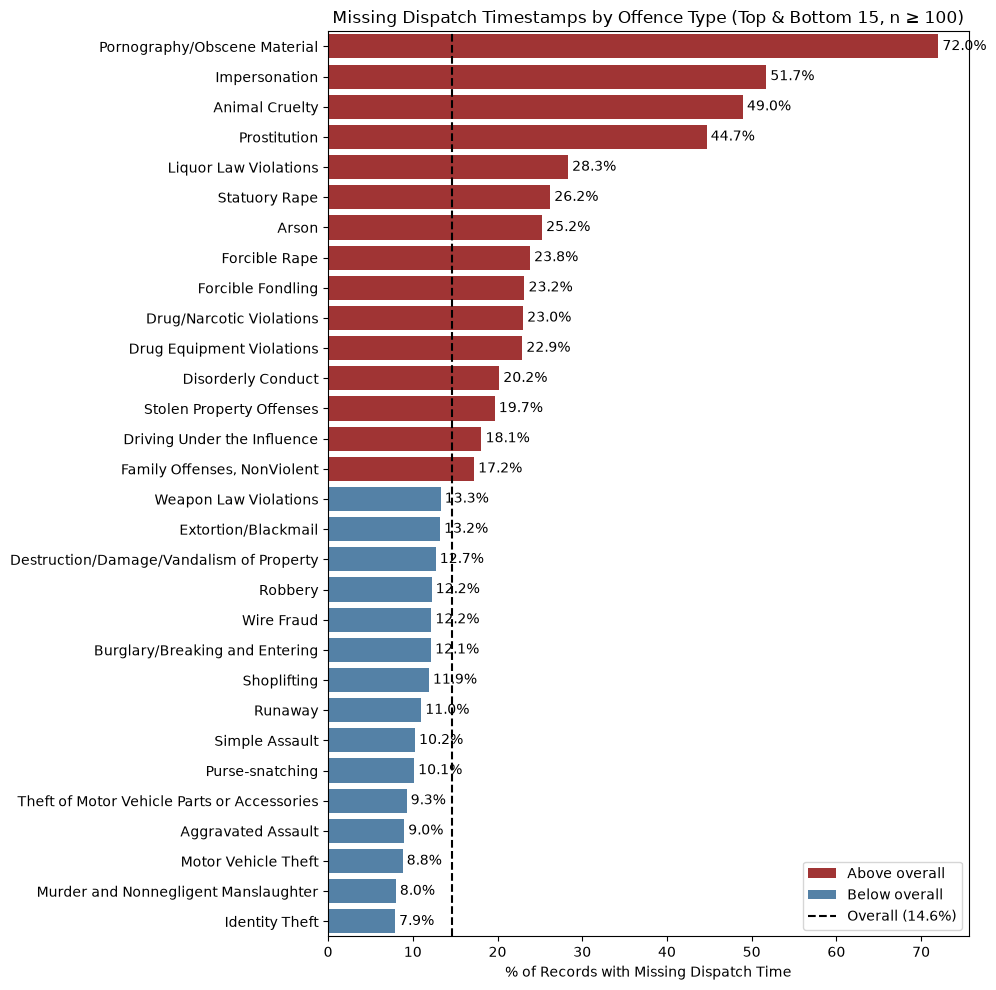

In [47]:
combined = pd.concat([offence_missing.head(15), offence_missing.tail(15)]).reset_index()
combined["Group"] = np.where(combined["Missing_%"] > overall_rate, "Above overall", "Below overall")
 
plt.figure(figsize=(10, 10))
ax = sns.barplot(data=combined, x="Missing_%", y="Crime Name 2", hue="Group",
                 palette={"Above overall": "firebrick", "Below overall": "steelblue"}, dodge=False)
ax.axvline(overall_rate, color="black", linestyle="--", label=f"Overall ({overall_rate:.1f}%)")
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", padding=3)
 
ax.set_title("Missing Dispatch Timestamps by Offence Type (Top & Bottom 15, n ≥ 100)")
ax.set_xlabel("% of Records with Missing Dispatch Time")
ax.set_ylabel("")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

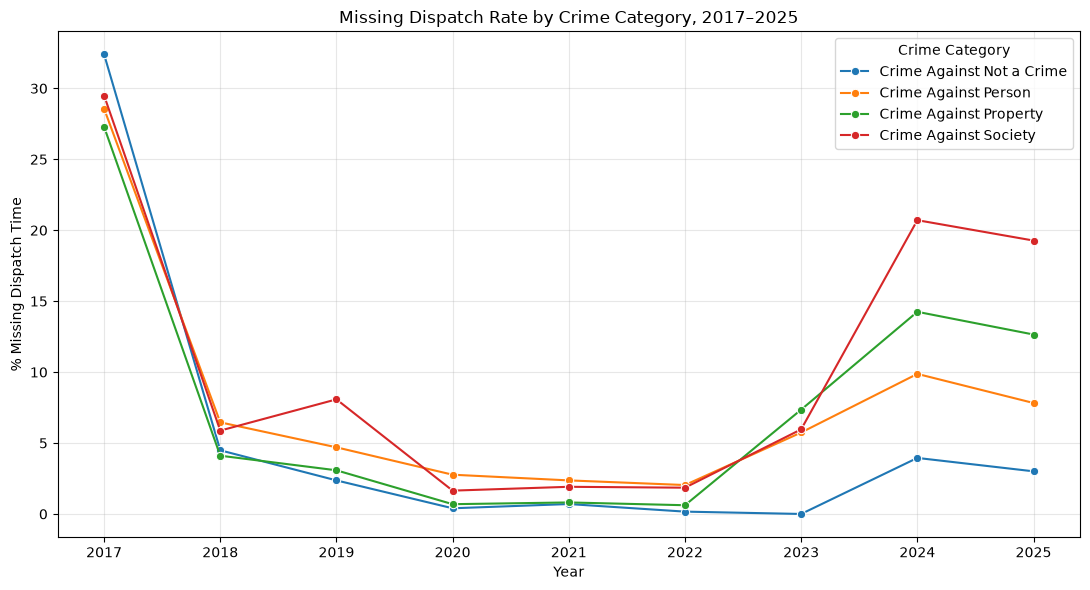

In [48]:
trend = (disp[disp["Year"].between(2017, 2025)]
         .groupby(["Year", "Crime Name 1"])["Dispatch_Missing"].mean().mul(100).reset_index())
 
plt.figure(figsize=(11, 6))
ax = sns.lineplot(data=trend, x="Year", y="Dispatch_Missing", hue="Crime Name 1", marker="o")
ax.set_title("Missing Dispatch Rate by Crime Category, 2017–2025")
ax.set_xlabel("Year")
ax.set_ylabel("% Missing Dispatch Time")
ax.legend(title="Crime Category")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

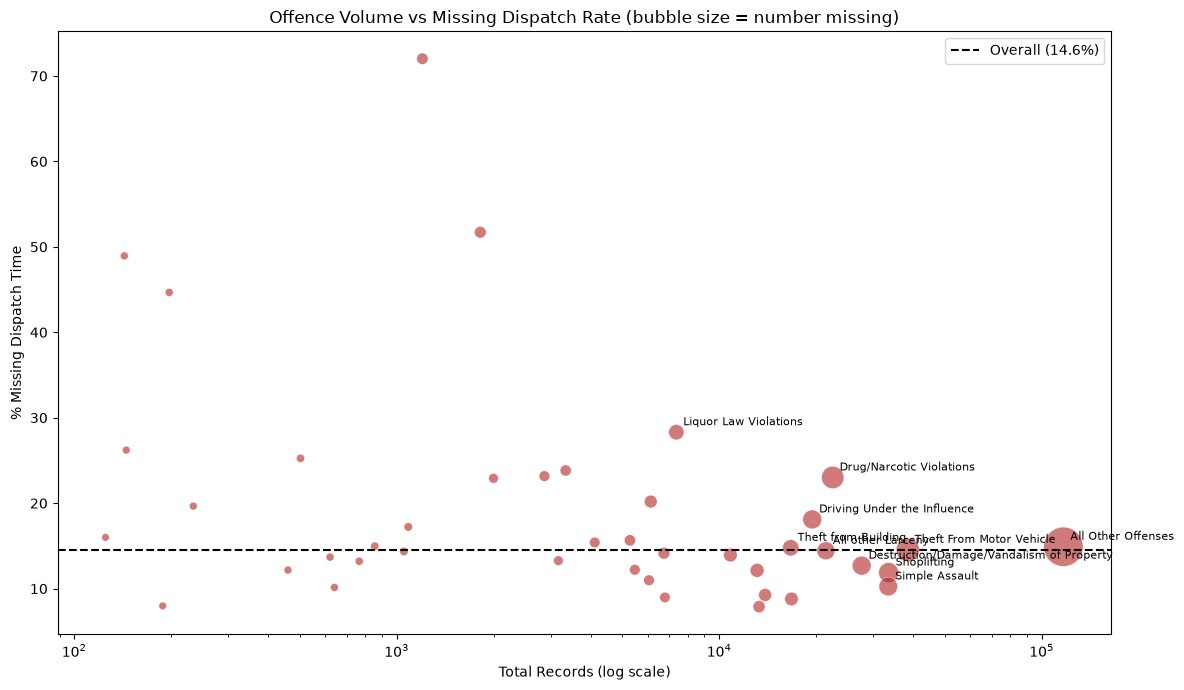

In [49]:
scatter_df = missing_by("Crime Name 2", min_n=100).reset_index()
 
plt.figure(figsize=(12, 7))
ax = sns.scatterplot(data=scatter_df, x="Total", y="Missing_%", size="Missing",
                     sizes=(30, 800), alpha=0.6, color="firebrick", legend=False)
ax.axhline(overall_rate, color="black", linestyle="--", label=f"Overall ({overall_rate:.1f}%)")
ax.set_xscale("log")
 
for _, r in scatter_df.nlargest(10, "Missing").iterrows():
    ax.annotate(r["Crime Name 2"], (r["Total"], r["Missing_%"]), fontsize=8,
                xytext=(5, 5), textcoords="offset points")
 
ax.set_title("Offence Volume vs Missing Dispatch Rate (bubble size = number missing)")
ax.set_xlabel("Total Records (log scale)")
ax.set_ylabel("% Missing Dispatch Time")
ax.legend()
plt.tight_layout()
plt.show()

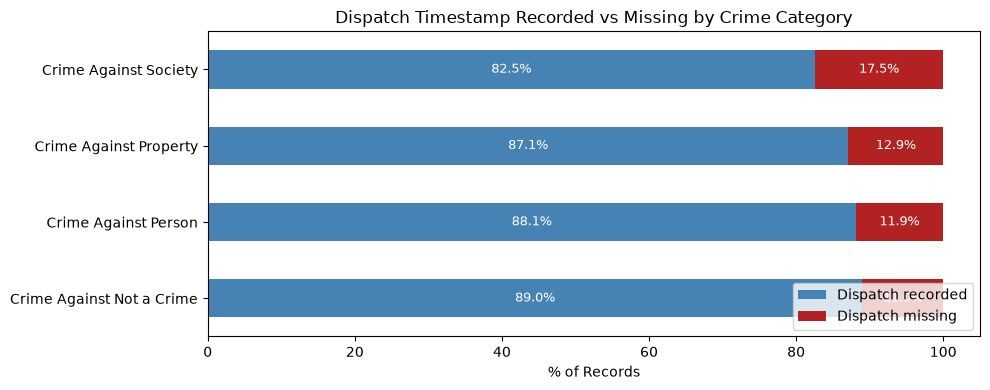

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
 
split = pd.crosstab(disp["Crime Name 1"], disp["Dispatch_Missing"], normalize="index").mul(100)
split.columns = ["Dispatch recorded", "Dispatch missing"]
split = split.sort_values("Dispatch missing")
 
ax = split.plot(kind="barh", stacked=True, figsize=(10, 4), color=["steelblue", "firebrick"])
for c in ax.containers:
    ax.bar_label(c, fmt="%.1f%%", label_type="center", color="white", fontsize=9)
ax.set_title("Dispatch Timestamp Recorded vs Missing by Crime Category")
ax.set_xlabel("% of Records")
ax.set_ylabel("")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

In [51]:
# %pip install scipy

In [52]:
from scipy.stats import chi2_contingency
 
contingency = pd.crosstab(disp["Crime Name 1"], disp["Dispatch_Missing"])
chi2, p, dof, expected = chi2_contingency(contingency)
 
print(f"Chi-square = {chi2:,.1f}, df = {dof}, p-value = {p:.3e}")
 
# Effect size (Cramér's V): 0.1 small, 0.3 medium, 0.5 large
n = contingency.to_numpy().sum()
cramers_v = np.sqrt(chi2 / (n * (min(contingency.shape) - 1)))
print(f"Cramér's V = {cramers_v:.3f}")

Chi-square = 2,087.5, df = 3, p-value = 0.000e+00
Cramér's V = 0.067


In [53]:
# Missing % by crime category and year
display(pd.crosstab(disp["Crime Name 1"], disp["Year"],
                    values=disp["Dispatch_Missing"], aggfunc="mean").mul(100).round(1))
 
# Missing % by crime category and district
display(pd.crosstab(disp["Crime Name 1"], disp["Police District Name"],
                    values=disp["Dispatch_Missing"], aggfunc="mean").mul(100).round(1))

Year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Crime Name 1,,,,,,,,,,,
Crime Against Not a Crime,100.0,32.4,4.5,2.4,0.4,0.7,0.2,0.0,3.9,3.0,3.9
Crime Against Person,97.5,28.6,6.5,4.7,2.8,2.4,2.0,5.7,9.9,7.8,7.3
Crime Against Property,98.9,27.3,4.1,3.1,0.7,0.8,0.6,7.4,14.2,12.6,10.3
Crime Against Society,99.4,29.5,5.9,8.1,1.6,1.9,1.9,6.0,20.7,19.3,21.1


Police District Name,BETHESDA,GERMANTOWN,MONTGOMERY VILLAGE,OTHER,ROCKVILLE,SILVER SPRING,TAKOMA PARK,WHEATON
Crime Name 1,,,,,,,,
Crime Against Not a Crime,5.9,10.8,12.1,NaN,9.7,10.2,20.3,13.5
Crime Against Person,10.9,11.8,12.0,0.0,12.5,11.2,9.8,13.2
Crime Against Property,12.5,14.9,14.4,0.0,12.2,12.5,8.8,12.4
Crime Against Society,16.1,15.9,16.4,0.0,23.2,16.1,13.8,17.2


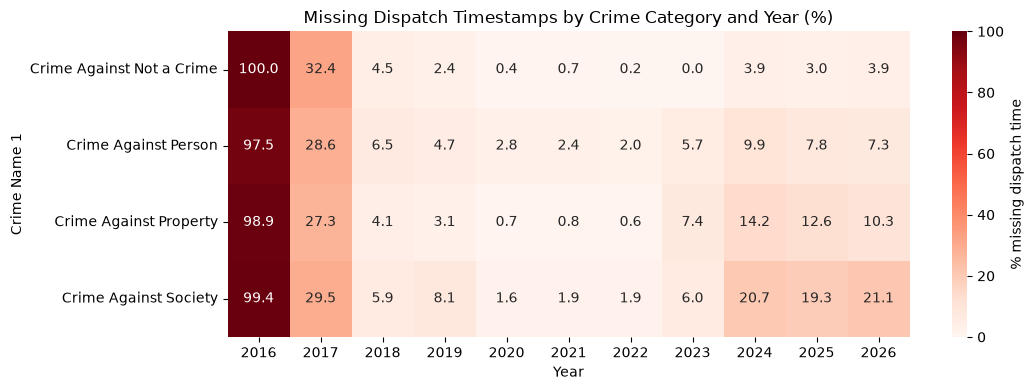

In [54]:
import seaborn as sns
import matplotlib.pyplot as plt
 
heat = pd.crosstab(disp["Crime Name 1"], disp["Year"],
                   values=disp["Dispatch_Missing"], aggfunc="mean").mul(100).round(1)
 
plt.figure(figsize=(11, 4))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% missing dispatch time"})
plt.title("Missing Dispatch Timestamps by Crime Category and Year (%)")
plt.tight_layout()
plt.show()

###	How does the proportion of incidents involving multiple victims differ between location types?

In [55]:
incidentclean = (
    df.drop_duplicates(subset=["Incident ID", "Offense Code"])
      .query("`Start Date/Time` >= '2016-07-01' and `Start Date/Time` <= '2026-09-10 23:59:59'")
      .groupby("Incident ID")
      .agg(Victims=("Victims", "max"),
           Place=("Place", "first"),
           Crime_Cat=("Crime Name 1", "first"))
      .reset_index()
)
incidentclean["Multi_Victim"] = incidentclean["Victims"] > 1
 
print(incidentclean["Victims"].value_counts().sort_index())
print(f"Overall multi-victim proportion: {incidentclean['Multi_Victim'].mean()*100:.2f}%")

Victims
1     458381
2       7658
3        921
4        284
5         86
6         23
7         23
8          5
9          2
22         1
Name: count, dtype: int64
Overall multi-victim proportion: 1.93%


In [57]:
overallmv = incidentclean["Multi_Victim"].mean() * 100
 
place_tbl = incidentclean.groupby("Place")["Multi_Victim"].agg(Incidents="size", Multi_Victim="sum")
place_tbl["Multi_%"] = (place_tbl["Multi_Victim"] / place_tbl["Incidents"] * 100).round(2)
place_tbl["Vs_Overall"] = (place_tbl["Multi_%"] / overallmv).round(2)
place_tbl = place_tbl[place_tbl["Incidents"] >= 200].sort_values("Multi_%", ascending=False)
 
display(place_tbl.head(15))
display(place_tbl.tail(15))

,Incidents,Multi_Victim,Multi_%,Vs_Overall
Place,,,,
Bar/Night Club,1649,147,8.91,4.63
Residence -Townhouse/Duplex,20891,1037,4.96,2.57
Residence - Apartment/Condo,45999,2259,4.91,2.55
Pool,377,16,4.24,2.20
Hospital/Emergency Care Center,3181,128,4.02,2.09
Theater,258,10,3.88,2.01
Field/ Open Space,431,14,3.25,1.69
Hotel/Motel/Etc.,3487,106,3.04,1.58
Restaurant,8047,239,2.97,1.54


,Incidents,Multi_Victim,Multi_%,Vs_Overall
Place,,,,
Parking Lot - Church,429,2,0.47,0.24
Residence - Driveway,14956,68,0.45,0.23
Retail - Clothing,3404,14,0.41,0.21
Bank - ATM,1831,7,0.38,0.20
Retail - Hardware,1348,5,0.37,0.19
Retail - Drug Store/Pharmacy,4886,18,0.37,0.19
Liquor Store - County,895,3,0.34,0.18
Parking Garage - County,2076,7,0.34,0.18
Bank/S&L/Credit Union,1699,5,0.29,0.15


In [58]:
incidentclean["Place_Group"] = incidentclean["Place"].str.split(" - ").str[0].str.strip()
 
group_tbl = incidentclean.groupby("Place_Group")["Multi_Victim"].agg(Incidents="size", Multi_Victim="sum")
group_tbl["Multi_%"] = (group_tbl["Multi_Victim"] / group_tbl["Incidents"] * 100).round(2)
group_tbl = group_tbl[group_tbl["Incidents"] >= 200].sort_values("Multi_%", ascending=False)
display(group_tbl)

,Incidents,Multi_Victim,Multi_%
Place_Group,,,
Bar/Night Club,1649,147,8.91
Residence -Townhouse/Duplex,20891,1037,4.96
Pool,377,16,4.24
Hospital/Emergency Care Center,3181,128,4.02
Theater,258,10,3.88
Field/ Open Space,431,14,3.25
Residence,127523,4002,3.14
Hotel/Motel/Etc.,3487,106,3.04
Restaurant,8047,239,2.97


In [61]:
from scipy.stats import chi2_contingency
 
mvdiffcheck = pd.crosstab(incidentclean.loc[incidentclean["Place_Group"].isin(group_tbl.index), "Place_Group"], incidentclean["Multi_Victim"])
chi2, p, dof, _ = chi2_contingency(mvdiffcheck)
cramers_v = np.sqrt(chi2 / (mvdiffcheck.to_numpy().sum() * (min(mvdiffcheck) - 1)))
print(f"χ² = {chi2:,.1f}, df = {dof}, p = {p:.3e}, Cramér's V = {cramers_v:.3f}")

χ² = 4,270.0, df = 39, p = 0.000e+00, Cramér's V = nan


C:\Users\isham\AppData\Local\Temp\ipykernel_45988\2087412200.py:5: RuntimeWarning: invalid value encountered in sqrt
  cramers_v = np.sqrt(chi2 / (mvdiffcheck.to_numpy().sum() * (min(mvdiffcheck) - 1)))


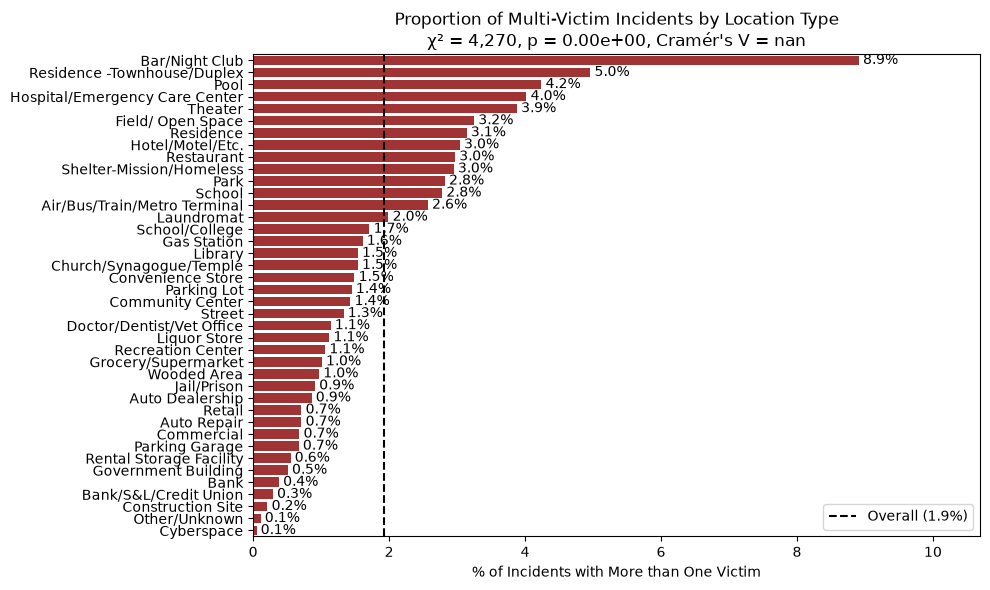

In [64]:
import matplotlib.pyplot as plt
import seaborn as sns
 
plot_df = group_tbl.reset_index()
 
plt.figure(figsize=(10, 6))
ax = sns.barplot(data=plot_df, x="Multi_%", y="Place_Group", color="firebrick")
ax.axvline(overallmv, color="black", linestyle="--", label=f"Overall ({overallmv:.1f}%)")
ax.bar_label(ax.containers[0], fmt="%.1f%%", padding=3)
ax.set_title(f"Proportion of Multi-Victim Incidents by Location Type\nχ² = {chi2:,.0f}, p = {p:.2e}, Cramér's V = {cramers_v:.3f}")
ax.set_xlabel("% of Incidents with More than One Victim")
ax.set_ylabel("")
ax.set_xlim(0, plot_df["Multi_%"].max() * 1.2)
ax.legend()
plt.tight_layout()
plt.show()

## easier

In [65]:
victim_crime = pd.crosstab(df_clean["Victims"], df_clean["Crime Name 2"], normalize="index").mul(100).round(1)
 
top_crime = pd.DataFrame({
    "Incidents": df_clean["Victims"].value_counts().sort_index(),
    "Top_Crime": victim_crime.idxmax(axis=1),
    "Top_Crime_%": victim_crime.max(axis=1)
})
display(top_crime)

,Incidents,Top_Crime,Top_Crime_%
Victims,,,
1,459508,All Other Offenses,25.4
2,7005,Simple Assault,86.8
3,748,Simple Assault,76.1
4,227,Simple Assault,67.8
5,65,Simple Assault,58.5
6,21,Aggravated Assault,52.4
7,20,Simple Assault,65.0
8,4,Aggravated Assault,50.0
9,2,Simple Assault,100.0


In [66]:
victim_place = pd.crosstab(df_clean["Victims"], df_clean["Place"], normalize="index").mul(100).round(1)
 
top_place = pd.DataFrame({
    "Incidents": df_clean["Victims"].value_counts().sort_index(),
    "Top_Place": victim_place.idxmax(axis=1),
    "Top_Place_%": victim_place.max(axis=1)
})
display(top_place)

,Incidents,Top_Place,Top_Place_%
Victims,,,
1,459508,Residence - Single Family,10.6
2,7005,Residence - Apartment/Condo,27.6
3,748,Residence - Apartment/Condo,19.4
4,227,Residence - Apartment/Condo,12.3
5,65,Residence - Apartment/Condo,15.4
6,21,Residence - Apartment/Condo,19.0
7,20,Residence - Apartment/Condo,15.0
8,4,Parking Lot - Residential,25.0
9,2,Restaurant,50.0


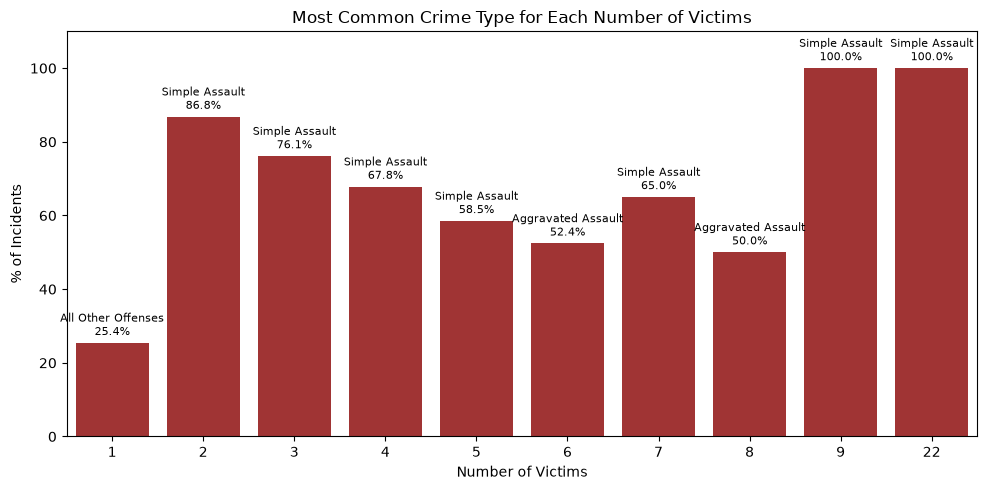

In [67]:
import matplotlib.pyplot as plt
import seaborn as sns
 
plot_df = top_crime.reset_index().rename(columns={"index": "Victims"})
 
plt.figure(figsize=(10, 5))
ax = sns.barplot(data=plot_df, x="Victims", y="Top_Crime_%", color="firebrick")
ax.bar_label(ax.containers[0], labels=[f"{c}\n{p}%" for c, p in zip(plot_df["Top_Crime"], plot_df["Top_Crime_%"])],
             fontsize=8, padding=3)
ax.set_title("Most Common Crime Type for Each Number of Victims")
ax.set_xlabel("Number of Victims")
ax.set_ylabel("% of Incidents")
ax.set_ylim(0, 110)
plt.tight_layout()
plt.show()